In [ ]:


import pandas as pd
import ast
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader


In [ ]:
# !conda env create -f environment.yml


In [ ]:
# UNCOMMENT WHEN RUNNING IN GOOGLE HERE #################
from google.colab import drive # uncomment when running in google
# Mount Google Drive
drive.mount('/content/drive') #
df = pd.read_csv(r'/content/drive/MyDrive/Colab Notebooks/7643 Project/train_and_validate.csv') # this is good for google so uncomment when u need it.
test_df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/7643 Project/test.csv')
df = df.rename(columns={'location': 'subcellularLocations'})
test_df = test_df.rename(columns={'location': 'subcellularLocations'})


#WHEN RUNNING ON LOCAL MACHINE
# df = pd.read_csv(r"train_and_validate.csv")
# df = df.rename(columns={'location': 'subcellularLocations'})
# test_df = pd.read_csv(r"test.csv")
# test_df = test_df.rename(columns={'location': 'subcellularLocations'})



Mounted at /content/drive


In [ ]:
def safe_eval(val):
    try:
        return ast.literal_eval(val)
    except (ValueError, SyntaxError):
        return [val]

df_copy = df.copy()
df_copy['subcellularLocations'] = df_copy['subcellularLocations'].apply(safe_eval)
df_exploded = df_copy.explode('subcellularLocations')
df_exploded = df_exploded.rename(columns={'subcellularLocations': 'subcellularLocationSingle'})
df_dropna = df_exploded.dropna(subset=['subcellularLocationSingle'])

df_biLstm = df_dropna.copy()
df_biLstm.to_csv('df_biLstm.csv', index=False)


In [ ]:
top_3_locations = df_biLstm['subcellularLocationSingle'].value_counts().nlargest(3).index.tolist()
print("Top 3 Locations:", top_3_locations)
df_bilstm_top3 = df_biLstm[df_biLstm['subcellularLocationSingle'].isin(top_3_locations)].reset_index(drop=True)
print("New dataset shape:", df_bilstm_top3.shape)
print(df_bilstm_top3['subcellularLocationSingle'].value_counts())

Top 3 Locations: ['Nucleus', 'Cytoplasm', 'Cell membrane']
New dataset shape: (12136, 4)
subcellularLocationSingle
Nucleus          4690
Cytoplasm        3930
Cell membrane    3516
Name: count, dtype: int64


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

import torch
import torch.nn as nn

from torch.utils.data import Dataset
vocab_size = 22
output_dim = 3

embedding_dim = 128
hidden_dim = 128
dropout = 0.6
weight_decay = 1e-5
learning_rate = 0.0005
batch_size = 16
num_epochs = 10
num_layers = 2


# DATASET LOADER
class ProteinDataset(Dataset):
    def __init__(self, sequences, labels, amino_acid_to_idx, label_to_idx):
        self.sequences = sequences
        self.labels = labels
        self.aa2idx = amino_acid_to_idx
        self.label2idx = label_to_idx

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
      sequence = self.sequences[idx]
      label = self.labels[idx]


      sequence_encoded = [self.aa2idx.get(aa, self.aa2idx['X']) for aa in sequence]


      label_idx = self.label2idx[label]

      return torch.tensor(sequence_encoded), torch.tensor(label_idx)




class ProteinBiLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, num_layers=1, dropout=0.5):
        super(ProteinBiLSTM, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.bilstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0
        )


        self.fc1 = nn.Linear(hidden_dim * 2, 128)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(128, output_dim)
        self.dropout = nn.Dropout(dropout)
        self.attention_fc = nn.Linear(hidden_dim * 2, 1)



    def forward(self, x):
        embedded = self.embedding(x)
        lstm_out, _ = self.bilstm(embedded)

        # mean_pooled = torch.mean(lstm_out, dim=1)
        # max_pooled, _ = torch.max(lstm_out, dim = 1)
        # pooled = torch.cat((mean_pooled, max_pooled), dim = 1)


        attention_scores = torch.softmax(self.attention_fc(lstm_out), dim=1)
        pooled = torch.sum(attention_scores * lstm_out, dim=1)


        hidden = self.fc1(pooled)
        hidden = self.relu(hidden)
        output = self.dropout(hidden)
        output = self.fc2(hidden)

        # output = self.fc2(hidden)

        return output


model = ProteinBiLSTM(
    vocab_size=vocab_size,
    embedding_dim=embedding_dim,
    hidden_dim=hidden_dim,
    output_dim=output_dim,
    num_layers=num_layers,
    dropout=dropout
).to(device)



In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)
amino_acid_to_idx = {
    'A': 0, 'C': 1, 'D': 2, 'E': 3, 'F': 4,
    'G': 5, 'H': 6, 'I': 7, 'K': 8, 'L': 9,
    'M': 10, 'N': 11, 'P': 12, 'Q': 13, 'R': 14,
    'S': 15, 'T': 16, 'V': 17, 'W': 18, 'Y': 19,
    'X': 20, '-': 21
}
location_to_idx = {
    'Nucleus': 0,
    'Cytoplasm': 1,
    'Cell membrane': 2
}
sequences = df_bilstm_top3['sequence'].tolist()
labels = df_bilstm_top3['subcellularLocationSingle'].tolist()

train_dataset = ProteinDataset(sequences, labels, amino_acid_to_idx, location_to_idx)
train_dataset

In [ ]:
from torch.nn.utils.rnn import pad_sequence

#PADDING THE DATA
def collate_fn(batch):
    sequences, labels = zip(*batch)

    padded_sequences = pad_sequence(sequences, batch_first=True, padding_value=amino_acid_to_idx['-'])

    labels = torch.stack(labels)

    return padded_sequences, labels


In [ ]:
#TRAIN TEST SPLIT THE DATA
from sklearn.model_selection import train_test_split
train_sequences, val_sequences, train_labels, val_labels = train_test_split(
    sequences, labels, test_size=0.2, random_state=42, stratify=labels
)
# TRAIN & TEST VALIDATION DATASETS
train_dataset = ProteinDataset(train_sequences, train_labels, amino_acid_to_idx, location_to_idx)
val_dataset = ProteinDataset(val_sequences, val_labels, amino_acid_to_idx, location_to_idx)

#
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)

In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    collate_fn=collate_fn
)


In [ ]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay =weight_decay )

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)
print(f"device {device}")

device cuda


In [ ]:
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []


for epoch in range(num_epochs):
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)

        optimizer.zero_grad()
        outputs = model(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        _, predicted = outputs.max(1)
        train_correct += (predicted == batch_y).sum().item()
        train_total += batch_y.size(0)

    avg_train_loss = train_loss / len(train_loader)
    train_accuracy = train_correct / train_total


    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            outputs = model(batch_x)
            loss = criterion(outputs, batch_y)

            val_loss += loss.item()
            _, predicted = outputs.max(1)
            val_correct += (predicted == batch_y).sum().item()
            val_total += batch_y.size(0)

    avg_val_loss = val_loss / len(val_loader)
    val_accuracy = val_correct / val_total


    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {avg_train_loss:.4f}, Acc: {train_accuracy:.4f} | Val Loss: {avg_val_loss:.4f}, Acc: {val_accuracy:.4f}")


Epoch 1/10 | Train Loss: 0.8805, Acc: 0.5469 | Val Loss: 0.7828, Acc: 0.6034
Epoch 2/10 | Train Loss: 0.7834, Acc: 0.6137 | Val Loss: 0.7633, Acc: 0.6306
Epoch 3/10 | Train Loss: 0.7629, Acc: 0.6245 | Val Loss: 0.7536, Acc: 0.6380
Epoch 4/10 | Train Loss: 0.7450, Acc: 0.6430 | Val Loss: 0.7413, Acc: 0.6466
Epoch 5/10 | Train Loss: 0.7316, Acc: 0.6507 | Val Loss: 0.7461, Acc: 0.6483
Epoch 6/10 | Train Loss: 0.7189, Acc: 0.6538 | Val Loss: 0.7609, Acc: 0.6458
Epoch 7/10 | Train Loss: 0.7090, Acc: 0.6650 | Val Loss: 0.7405, Acc: 0.6421
Epoch 8/10 | Train Loss: 0.6967, Acc: 0.6660 | Val Loss: 0.7407, Acc: 0.6503
Epoch 9/10 | Train Loss: 0.6825, Acc: 0.6730 | Val Loss: 0.7519, Acc: 0.6433
Epoch 10/10 | Train Loss: 0.6697, Acc: 0.6744 | Val Loss: 0.7469, Acc: 0.6417


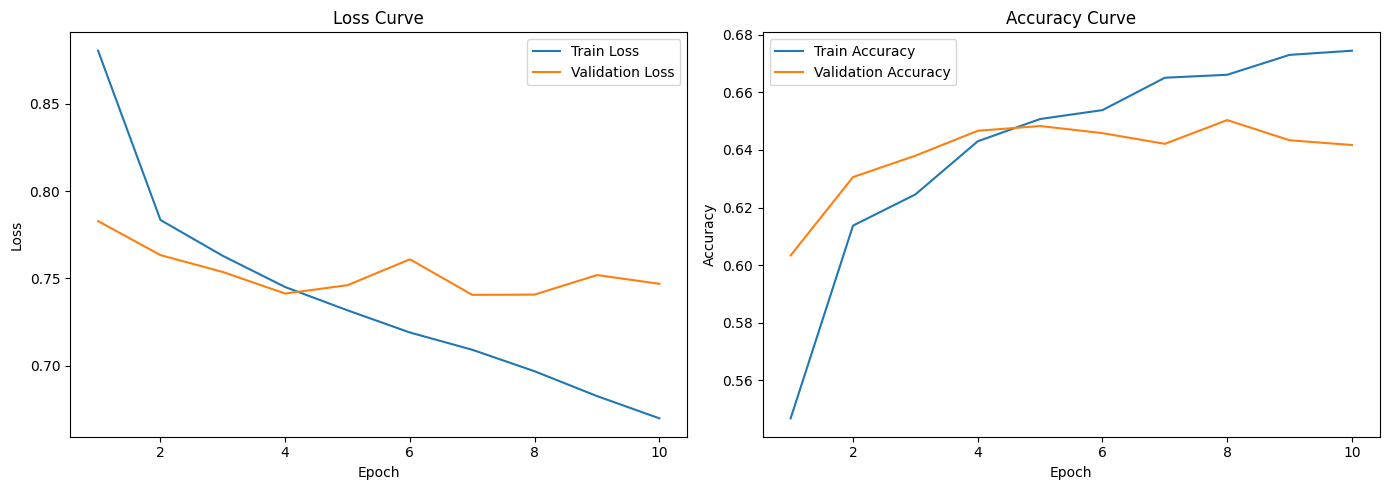

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(14, 5))

# Loss Plot
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label='Train Loss')
plt.plot(epochs, val_losses, label='Validation Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Curve")
plt.legend()
# plt.grid(True)

# Accuracy Plot
plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, label='Train Accuracy')
plt.plot(epochs, val_accuracies, label='Validation Accuracy')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Curve")
plt.legend()
# plt.grid(True)

plt.tight_layout()
plt.show()


In [ ]:
test_df = test_df.copy()
test_df['subcellularLocations'] = test_df['subcellularLocations'].apply(safe_eval)
test_exploded = test_df.explode('subcellularLocations')
test_exploded = test_exploded.rename(columns={'subcellularLocations': 'subcellularLocationSingle'})
test_exploded = test_exploded.dropna(subset=['subcellularLocationSingle'])


test_df_top3 = test_exploded[test_exploded['subcellularLocationSingle'].isin(location_to_idx.keys())]


test_sequences = test_df_top3['sequence'].tolist()
test_labels = test_df_top3['subcellularLocationSingle'].tolist()


In [ ]:
test_dataset = ProteinDataset(test_sequences, test_labels, amino_acid_to_idx, location_to_idx)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    collate_fn=collate_fn
)


In [ ]:
model.eval()
test_loss = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():
    for batch_x, batch_y in test_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)

        outputs = model(batch_x)
        loss = criterion(outputs, batch_y)

        test_loss += loss.item()
        _, predicted = outputs.max(1)
        test_correct += (predicted == batch_y).sum().item()
        test_total += batch_y.size(0)

avg_test_loss = test_loss / len(test_loader)
test_accuracy = test_correct / test_total

print(f"Test Loss: {avg_test_loss:.4f}, Test Accuracy: {test_accuracy:.4f}")


✅ Test Loss: 0.5626, Test Accuracy: 0.7482
